### data generation
hide this code chunk

In [1]:
import numpy as np
import pandas as pd

rng = np.random.default_rng(42)
n = 800

area = rng.integers(50, 251, n)
temp = rng.uniform(-15, 25, n).round(1)
occupants = rng.integers(1, 7, n)
heating = rng.choice(["gas", "heat pump", "electric"], n)

cold = np.maximum(18 - temp, 0)
heating_factor = np.select(
    [heating == "gas", heating == "heat pump"],
    [0.05, 0.45],
    default=1.0,
)

daily_kwh = (
    4 + 1.5 * occupants + 0.015 * area
    + 0.012 * area * cold * heating_factor
    + rng.normal(0, 1.5, n)
)

df = pd.DataFrame({
    "floor_area": [f"{value} m2" for value in area],
    "outdoor_temp_c": temp,
    "occupants": occupants,
    "heating_type": [
        f" {value.upper()} " if messy else value
        for value, messy in zip(heating, rng.random(n) < 0.25)
    ],
    "daily_kwh": daily_kwh.round(2),
})

df.loc[rng.random(n) < 0.08, "floor_area"] = "unknown"
df.loc[rng.random(n) < 0.08, "outdoor_temp_c"] = np.nan
df.loc[rng.random(n) < 0.08, "heating_type"] = None

In [2]:
df.head()

,floor_area,outdoor_temp_c,occupants,heating_type,daily_kwh
0,67 m2,NaN,1,electric,21.77
1,205 m2,21.7,4,electric,14.44
2,181 m2,16.3,5,electric,16.10
3,138 m2,-10.6,4,gas,14.01
4,137 m2,24.9,3,GAS,9.68


### instructions
1. Inspect and split. Print the data types, missing counts, and unique heating labels. Make an 80/20 train/test split with seed 42.
2. Write a reusable cleaning function. Convert "120 m2" to 120 and "unknown" to NaN. Normalize the heating labels and give the column pandas category dtype. Keep missing values as missing so you practise LightGBM’s native handling.
3. Build two baselines. Compare a constant prediction based on the training median with a default LGBMRegressor. Use MAE in kWh.
4. Make one purposeful change. Compare the default model with a smaller num_leaves on the same shuffled CV folds within the training set. Report both training and CV MAE so you can see whether the smaller model reduced overfitting. Pick the model using CV, refit it on the full training split, and report test MAE for it and the median baseline.
5. Stretch goal. Before checking test scores, add one feature that captures how floor area and cold weather interact. Compare its effect on CV MAE with the effect of tuning num_leaves.

In [3]:
print(type(df["floor_area"][0]))
print(type(df["outdoor_temp_c"][0]))
print(type(df["occupants"][0]))
print(type(df["heating_type"][0]))
print(type(df["daily_kwh"][0]))
print("\n\n")

print(df.isna().sum())

print(df["heating_type"].unique())

df["heating_type"] = df["heating_type"].str.strip().str.lower()
df["floor_area"] = df["floor_area"].str.removesuffix("m2").str.strip()
print(df["floor_area"])

<class 'str'>
<class 'numpy.float64'>
<class 'numpy.int64'>
<class 'numpy.str_'>
<class 'numpy.float64'>



floor_area         0
outdoor_temp_c    64
occupants          0
heating_type      65
daily_kwh          0
dtype: int64
<StringArray>
['electric', 'gas', ' GAS ', 'heat pump', nan, ' HEAT PUMP ', ' ELECTRIC ']
Length: 7, dtype: str
0           67
1          205
2          181
3          138
4          137
        ...   
795        109
796        244
797        142
798        113
799    unknown
Name: floor_area, Length: 800, dtype: str


In [4]:
raw = df["floor_area"]
known_missing = raw.eq("unknown").fillna(False)

area_m2 = pd.to_numeric(
    raw.str.replace(r"\s*m2$", "", regex=True),
    errors="coerce",
)

# Find values that failed conversion, excluding known missing values.
unexpected = raw.notna() & ~known_missing & area_m2.isna()
print(raw[unexpected].value_counts())

df["area_m2"] = area_m2
print(df["area_m2"])

df["heating_type"] = df["heating_type"].astype("category")

Series([], Name: count, dtype: int64)
0       67.0
1      205.0
2      181.0
3      138.0
4      137.0
       ...  
795    109.0
796    244.0
797    142.0
798    113.0
799      NaN
Name: area_m2, Length: 800, dtype: float64


In [5]:
print(list(df))

from sklearn.model_selection import train_test_split
X_train, X_t, y_train, y_t = train_test_split(
    df[['outdoor_temp_c', 'occupants', 'heating_type', 'area_m2']],
    df['daily_kwh'], 
    test_size=0.2, 
    shuffle=True, 
    random_state=42
)

['floor_area', 'outdoor_temp_c', 'occupants', 'heating_type', 'daily_kwh', 'area_m2']


In [6]:
print(X_train)


     outdoor_temp_c  occupants heating_type  area_m2
264            -1.3          2    heat pump    248.0
615            -7.9          3          gas    178.0
329             5.6          3          gas    161.0
342            19.5          4          gas    174.0
394           -13.8          1          gas    194.0
..              ...        ...          ...      ...
71              4.0          1    heat pump     88.0
106            -2.4          3          gas    206.0
270            -9.5          5          gas    109.0
435             7.7          4    heat pump     74.0
102            21.8          5    heat pump    211.0

[640 rows x 4 columns]


5. Stretch goal. Before checking test scores, add one feature that captures how floor area and cold weather interact. Compare its effect on CV MAE with the effect of tuning num_leaves.

In [7]:
from lightgbm import LGBMRegressor
from sklearn.metrics import mean_absolute_error

baseline = np.median(y_train)
print(baseline)
model = LGBMRegressor()
model.fit(X_train, y_train)
y_pred = model.predict(X_t)
mae_model = mean_absolute_error(y_t, y_pred)
print(mae_model)
mae_baseline = mean_absolute_error(y_t, [baseline]*len(y_t))
print(mae_baseline)

16.975
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000639 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 335
[LightGBM] [Info] Number of data points in the train set: 640, number of used features: 4
[LightGBM] [Info] Start training from score 23.920344
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive g

In [8]:
from sklearn.model_selection import GridSearchCV, KFold 

cv = KFold(
    n_splits=5, 
    shuffle=True,
    random_state=42
)

param_grid = [{
        "num_leaves": [7, 15, 31], 
        "min_child_samples": [10, 20, 40],
        "learning_rate": [0.10],
        "n_estimators": [100]
    }, {
        "num_leaves": [7, 15, 31], 
        "min_child_samples": [10, 20, 40],
        "learning_rate": [0.05],
        "n_estimators": [200]
    },]

search = GridSearchCV(
    LGBMRegressor(),
    param_grid=param_grid,
    scoring="neg_mean_absolute_error",
    cv=cv
)

In [9]:
help(LGBMRegressor)

Help on class LGBMRegressor in module lightgbm.sklearn:

class LGBMRegressor(sklearn.base.RegressorMixin, LGBMModel)
 |  LGBMRegressor(
 |      *,
 |      boosting_type: str = 'gbdt',
 |      num_leaves: int = 31,
 |      max_depth: int = -1,
 |      learning_rate: float = 0.1,
 |      n_estimators: int = 100,
 |      subsample_for_bin: int = 200000,
 |      objective: Optional[Union[str, _LGBM_ScikitCustomObjectiveFunction]] = None,
 |      class_weight: Optional[Union[Dict, str]] = None,
 |      min_split_gain: float = 0.0,
 |      min_child_weight: float = 0.001,
 |      min_child_samples: int = 20,
 |      subsample: float = 1.0,
 |      subsample_freq: int = 0,
 |      colsample_bytree: float = 1.0,
 |      reg_alpha: float = 0.0,
 |      reg_lambda: float = 0.0,
 |      random_state: Optional[Union[int, np.random.RandomState, np.random.Generator]] = None,
 |      n_jobs: Optional[int] = None,
 |      importance_type: str = 'split',
 |      **kwargs: Any
 |  ) -> None
 |
 |  Light

In [10]:
search.fit(X_train, y_train)

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000193 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 269
[LightGBM] [Info] Number of data points in the train set: 512, number of used features: 4
[LightGBM] [Info] Start training from score 23.953731
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000199 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 266
[LightGBM] [Info] Number of data points in the train set: 512, number of used features: 4
[LightGBM] [Info] Start training from score 23.810020
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000206 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 269
[LightGBM] [Info] Number of data points in the train set: 512, number of used features: 4
[LightGBM] [Info] Start training from

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",LGBMRegressor()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","[{'learning_rate': [0.1], 'min_child_samples': [10, 20, ...], 'n_estimators': [100], 'num_leaves': [7, 15, ...]}, {'learning_rate': [0.05], 'min_child_samples': [10, 20, ...], 'n_estimators': [200], 'num_leaves': [7, 15, ...]}]"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_mean_absolute_error'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to us

In [11]:
search.best_params_
search.best_score_

np.float64(-3.7356208001325846)

In [12]:
s_pred = search.predict(X_t)

print("MAE")
grid_model = mean_absolute_error(y_t, s_pred)
print(f"grid search: {grid_model}")
mae_model = mean_absolute_error(y_t, y_pred)
print(f"basic model: {mae_model}")
mae_baseline = mean_absolute_error(y_t, [baseline]*len(y_t))
print(f"baseline: {mae_baseline}")

MAE
grid search: 3.400656875741035
basic model: 3.8207614491775788
baseline: 11.106750000000002


In [13]:
import matplotlib.pyplot as plt 

# late stage data exploration lol
train = X_train.assign(daily_kwh=y_train)
electric = train.loc[train["heating_type"].eq("electric")].copy()
electric = electric.dropna(subset=["outdoor_temp_c", "area_m2"])
# print(electric)

med = electric["area_m2"].median()
electric["size"] = np.where(
    electric["area_m2"] < med, "small", "large"
)

electric["temp_band"] = (electric["outdoor_temp_c"] // 5) * 5
# print(electric)

usage = electric.groupby(["temp_band", "size"])["daily_kwh"].median().unstack("size")
print(usage)

size        large   small
temp_band                
-15.0      76.840  42.935
-10.0      70.865  45.040
-5.0       57.930  31.050
 0.0       48.915  29.155
 5.0       39.280  24.210
 10.0      25.780  18.095
 15.0      15.385  11.860
 20.0      12.265  11.100
 25.0      11.650     NaN


<Axes: xlabel='start of temp band', ylabel='median daily electricity use (kWh)'>

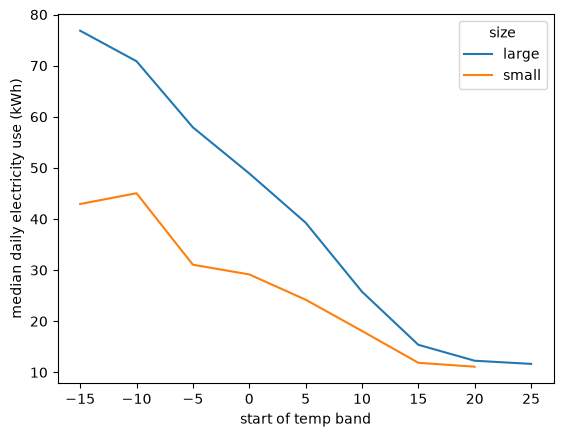

In [14]:
usage.plot(
    xlabel="start of temp band",
    ylabel="median daily electricity use (kWh)",
)

In [15]:
df["area_temp"] = df["area_m2"] * df["outdoor_temp_c"]

search2 = GridSearchCV(
    LGBMRegressor(),
    param_grid=param_grid,
    scoring="neg_mean_absolute_error",
    cv=cv
)

In [20]:
train_cold = (20 - X_train["outdoor_temp_c"]).clip(lower=0)
test_cold = (20 - X_t["outdoor_temp_c"]).clip(lower=0)

X_train = X_train.assign(
    area_temp=X_train["area_m2"] * train_cold
)
X_t = X_t.assign(
    area_temp=X_t["area_m2"] * test_cold
)

print(X_train)

     outdoor_temp_c  occupants heating_type  area_m2  area_temp
264            -1.3          2    heat pump    248.0     5282.4
615            -7.9          3          gas    178.0     4966.2
329             5.6          3          gas    161.0     2318.4
342            19.5          4          gas    174.0       87.0
394           -13.8          1          gas    194.0     6557.2
..              ...        ...          ...      ...        ...
71              4.0          1    heat pump     88.0     1408.0
106            -2.4          3          gas    206.0     4614.4
270            -9.5          5          gas    109.0     3215.5
435             7.7          4    heat pump     74.0      910.2
102            21.8          5    heat pump    211.0        0.0

[640 rows x 5 columns]


In [21]:
search2.fit(X_train, y_train)
search2_pred = search2.predict(X_t)
print(search2.best_params_)

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000225 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 396
[LightGBM] [Info] Number of data points in the train set: 512, number of used features: 5
[LightGBM] [Info] Start training from score 23.953731
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000181 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 392
[LightGBM] [Info] Number of data points in the train set: 512, number of used features: 5
[LightGBM] [Info] Start training from score 23.810020
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000223 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 397
[LightGBM] [Info] Number of data points in the train set: 512, number of used features: 5
[LightGBM] [Info] Start training from

In [22]:
print("MAE")
grid_model = mean_absolute_error(y_t, s_pred)
print(f"grid search: {grid_model}")
mae_model = mean_absolute_error(y_t, y_pred)
print(f"basic model: {mae_model}")
mae_baseline = mean_absolute_error(y_t, [baseline]*len(y_t))
print(f"baseline: {mae_baseline}")

search2_mae = mean_absolute_error(y_t, search2_pred)
print(f"grid search + new feat: {search2_mae}")

MAE
grid search: 3.400656875741035
basic model: 3.8207614491775788
baseline: 11.106750000000002
grid search + new feat: 3.3955514066188206
